# Sentiment Classification

Train and compare three models on the same test set:
1. Logistic Regression + TF-IDF (baseline)
2. XGBoost + TF-IDF (with hyperparameter tuning)
3. DistilBERT fine-tuned (transformer approach — runs on Colab)

In [2]:
import sys
from pathlib import Path

project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
import numpy as np
import joblib
from sklearn.preprocessing import LabelEncoder

from config import (
    TRAIN_CSV, VAL_CSV, TEST_CSV, TARGET_COL,
    TFIDF_MAX_FEATURES, TFIDF_NGRAM_RANGE, RANDOM_STATE, MODELS_DIR
)
from src.embeddings import build_tfidf
from src.training import train_logistic_regression, train_xgboost, apply_smote
from src.evaluation import evaluate_model, plot_confusion_matrix, compare_models

# Load data
train = pd.read_csv(TRAIN_CSV)
val = pd.read_csv(VAL_CSV)
test = pd.read_csv(TEST_CSV)

for split in [train, val, test]:
    split["review_clean"] = split["review_clean"].fillna("")
    split["review_heavy"] = split["review_heavy"].fillna("")

# Encode labels: Recommended=1, Not Recommended=0
le = LabelEncoder()
y_train = le.fit_transform(train[TARGET_COL])
y_val = le.transform(val[TARGET_COL])
y_test = le.transform(test[TARGET_COL])

print(f"Classes: {le.classes_}")
print(f"Train: {len(y_train)} | Val: {len(y_val)} | Test: {len(y_test)}")

Classes: ['Not Recommended' 'Recommended']
Train: 6226 | Val: 1335 | Test: 1335


In [3]:
# Build TF-IDF (fit on train only!)
tfidf_vec, X_train_tfidf = build_tfidf(
    train["review_heavy"],
    max_features=TFIDF_MAX_FEATURES,
    ngram_range=TFIDF_NGRAM_RANGE
)
X_val_tfidf = tfidf_vec.transform(val["review_heavy"])
X_test_tfidf = tfidf_vec.transform(test["review_heavy"])

# Apply SMOTE on training data
X_train_smote, y_train_smote = apply_smote(X_train_tfidf, y_train, random_state=RANDOM_STATE)

Before SMOTE: [1265 4961]
After SMOTE:  [4961 4961]


## 1. Logistic Regression

Best C: 10 | Best CV F1: 0.8562

  Logistic Regression
                 precision    recall  f1-score   support

Not Recommended       0.52      0.75      0.61       271
    Recommended       0.93      0.83      0.87      1064

       accuracy                           0.81      1335
      macro avg       0.73      0.79      0.74      1335
   weighted avg       0.85      0.81      0.82      1335



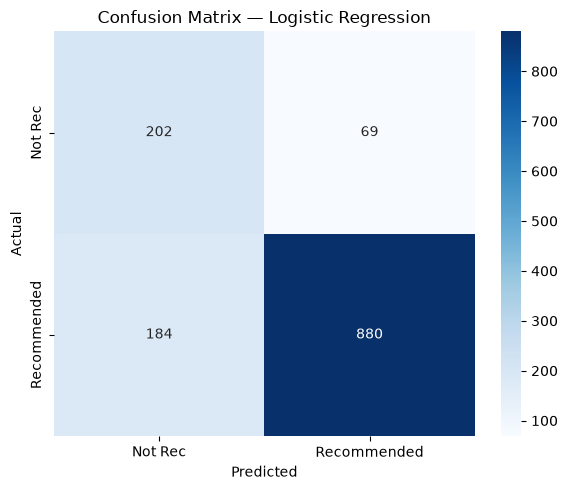

In [4]:
# Train Logistic Regression on SMOTE-balanced data
lr_model = train_logistic_regression(X_train_smote, y_train_smote, random_state=RANDOM_STATE)

# Evaluate on test set
y_pred_lr = evaluate_model(lr_model, X_test_tfidf, y_test, "Logistic Regression")
plot_confusion_matrix(y_test, y_pred_lr, "Logistic Regression")

## 2. XGBoost

c:\Users\user\steam-reviews-nlp\venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [20:33:30] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best params: {'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 200} | Best CV F1: 0.8667

  XGBoost
                 precision    recall  f1-score   support

Not Recommended       0.66      0.53      0.59       271
    Recommended       0.89      0.93      0.91      1064

       accuracy                           0.85      1335
      macro avg       0.77      0.73      0.75      1335
   weighted avg       0.84      0.85      0.84      1335



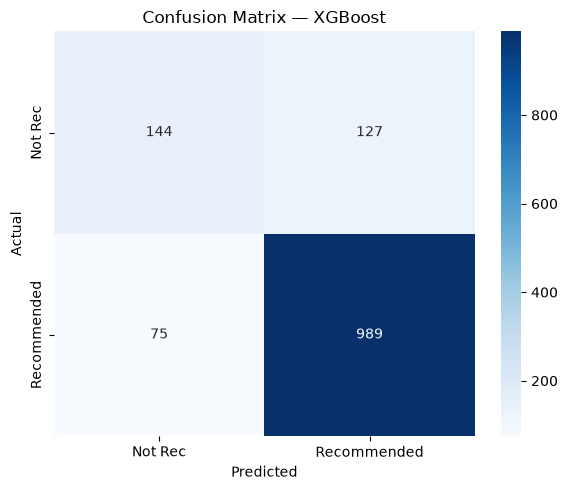

In [5]:
# Train XGBoost on SMOTE-balanced data
xgb_model = train_xgboost(X_train_smote, y_train_smote, random_state=RANDOM_STATE)

# Evaluate on test set
y_pred_xgb = evaluate_model(xgb_model, X_test_tfidf, y_test, "XGBoost")
plot_confusion_matrix(y_test, y_pred_xgb, "XGBoost")

## 3. Model Comparison (Traditional ML)

In [6]:
# Compare traditional ML models on the same test set
results = {
    "Logistic Regression": y_pred_lr,
    "XGBoost": y_pred_xgb,
}

comparison_df = compare_models(results, y_test)

# Save best traditional model
joblib.dump(xgb_model, MODELS_DIR / "xgboost_sentiment.joblib")
joblib.dump(tfidf_vec, MODELS_DIR / "tfidf_vectorizer.joblib")
print(f"\nSaved XGBoost and TF-IDF vectorizer to {MODELS_DIR}")


Model Comparison:
              Model  Accuracy     F1  Precision  Recall
            XGBoost    0.8487 0.9073     0.8862  0.9295
Logistic Regression    0.8105 0.8743     0.9273  0.8271

Saved XGBoost and TF-IDF vectorizer to C:\Users\user\steam-reviews-nlp\models


## 3. DistilBERT (Fine-tuned)

**Note:** DistilBERT fine-tuning requires GPU. 
Run on Google Colab — see notebook instructions.
Results will be added to the comparison table after training.

In [7]:
# Final comparison — all three models
from src.evaluation import compare_models

results = {
    "Logistic Regression": y_pred_lr,
    "XGBoost": y_pred_xgb,
}

# Add DistilBERT results manually (trained on Colab)
# Test set metrics: Accuracy=0.8929, F1=0.9328, Precision=0.93, Recall=0.93
distilbert_results = {
    "Model": "DistilBERT (fine-tuned)",
    "Accuracy": 0.8929,
    "F1": 0.9328,
    "Precision": 0.93,
    "Recall": 0.93,
}

comparison_df = compare_models(results, y_test)

import pandas as pd
bert_row = pd.DataFrame([distilbert_results])
comparison_df = pd.concat([comparison_df, bert_row], ignore_index=True)
comparison_df = comparison_df.sort_values("F1", ascending=False)

print("\n\nFinal Model Comparison (all three):")
print(comparison_df.to_string(index=False, float_format="%.4f"))


Model Comparison:
              Model  Accuracy     F1  Precision  Recall
            XGBoost    0.8487 0.9073     0.8862  0.9295
Logistic Regression    0.8105 0.8743     0.9273  0.8271


Final Model Comparison (all three):
                  Model  Accuracy     F1  Precision  Recall
DistilBERT (fine-tuned)    0.8929 0.9328     0.9300  0.9300
                XGBoost    0.8487 0.9073     0.8862  0.9295
    Logistic Regression    0.8105 0.8743     0.9273  0.8271


## Classification Summary

| Model | Accuracy | F1 | Not Rec Precision | Not Rec Recall |
|-------|----------|----|--------------------|----------------|
| DistilBERT | 89.3% | 0.933 | 74% | 74% |
| XGBoost | 84.9% | 0.907 | 66% | 53% |
| Logistic Regression | 81.0% | 0.874 | 52% | 75% |

Key findings:
- DistilBERT outperforms traditional models in all metrics
- Contextual understanding helps with ambiguous/short reviews
- XGBoost is a strong alternative when GPU is not available
- SMOTE + class weights effectively handle the 80/20 imbalance